In [1]:
%pip install -q landingai pillow matplotlib gTTS

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install landingai

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install pillow==10.4.0

Note: you may need to restart the kernel to use updated packages.


In [4]:
import io
import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)

# Test Pillow's JPEG encoder independently of LandingAI
buffer = io.BytesIO()
test_image = Image.new("RGB", (10, 10), color="red")
test_image.save(buffer, format="JPEG")

print("JPEG encoding successful:", len(buffer.getvalue()), "bytes")

Pillow version: 10.4.0
JPEG encoding successful: 633 bytes


In [6]:

import os
from dotenv import load_dotenv
from landingai.predict import Predictor

# Load environment variables from .env
load_dotenv()

# Get API key
API_KEY = os.getenv("LANDINGAI_API_KEY")

# Check API key
if not API_KEY:
    raise ValueError("LandingAI API key not found. Check your .env file.")

# Your new endpoint ID
ENDPOINT_ID = "bc57c7e1-cb34-46b0-942e-4b47245bddc0"

# Initialize LandingAI predictor
predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized successfully!")


LandingAI predictor initialized successfully!


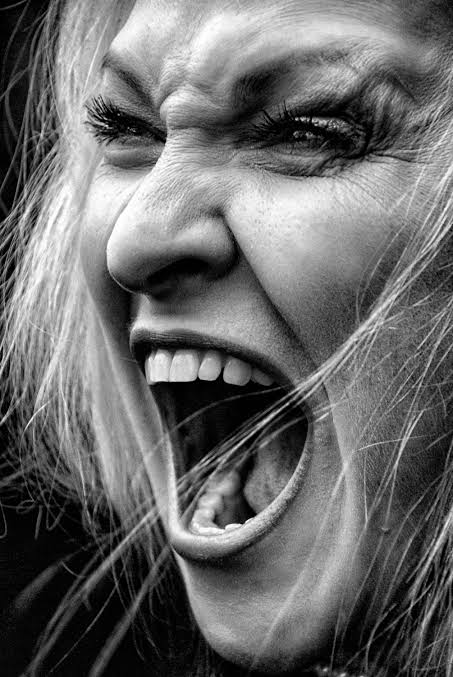

Image size: (453, 677)
Image array shape: (677, 453, 3)


: 

In [ ]:

from PIL import Image
import io
import numpy as np
from IPython.display import display
from tkinter import Tk, filedialog

# Select image from Mac
root = Tk()
root.withdraw()
root.attributes('-topmost', True)

image_path = filedialog.askopenfilename(
    title="Select Medicine Label Image",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.webp")
    ]
)

root.destroy()

if not image_path:
    raise ValueError("No image selected.")

# Load image
with Image.open(image_path) as im:
    image = im.convert("RGB").copy()

# Display image
display(image)

# Convert image into NumPy array
image_array = np.array(image)

print("Image size:", image.size)
print("Image array shape:", image_array.shape)


In [3]:
import os
import numpy as np
from dotenv import load_dotenv
from landingai.predict import Predictor

load_dotenv(".env", override=True)

API_KEY = os.getenv("LANDINGAI_API_KEY")
ENDPOINT_ID = os.getenv("LANDINGAI_ENDPOINT_ID")

assert API_KEY, "API key missing"
assert ENDPOINT_ID, "Endpoint ID missing"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("Predictor initialized!")

Predictor initialized!


In [5]:

import os
from dotenv import load_dotenv
from PIL import Image
import matplotlib.pyplot as plt
from landingai.predict import Predictor

# 1. Load credentials
load_dotenv(".env", override=True)

API_KEY = os.getenv("LANDINGAI_API_KEY")
ENDPOINT_ID = os.getenv("LANDINGAI_ENDPOINT_ID")

if not API_KEY:
    raise ValueError("API key missing from .env")

if not ENDPOINT_ID:
    raise ValueError("Endpoint ID missing from .env")

# 2. Initialize predictor
predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized!")

# 3. Load image
image_path = "1.jpeg"

if not os.path.exists(image_path):
    raise FileNotFoundError(f"Image not found: {image_path}")

image = Image.open(image_path).convert("RGB")

# 4. Predict emotion
print("\nAnalyzing facial expression...")

predictions = predictor.predict(image)

# 5. Display predictions
if predictions:

    top_pred = max(predictions, key=lambda p: p.score)

    print("\nPredicted Emotion:", top_pred.label_name)
    print(f"Confidence: {top_pred.score * 100:.2f}%")

    print("\nAll predictions:")

    for pred in predictions:
        print(
            f"- {pred.label_name}: "
            f"{pred.score * 100:.2f}%"
        )

else:
    top_pred = None
    print("No emotion detected.")

# 6. Display image and result
plt.figure(figsize=(7, 6))
plt.imshow(image)
plt.axis("off")

if top_pred:
    plt.title(
        f"Predicted Expression: {top_pred.label_name}\n"
        f"Confidence: {top_pred.score * 100:.1f}%"
    )

plt.show()


LandingAI predictor initialized!

Analyzing facial expression...


Request failed with status code 404: Not Found
Response detail:
{'content_length': 92,
 'data': {'detail': 'EndpointMissing - There is no endpoint id '
                    '34c8db94-54cf-4f14-a1c8-08432086a24b.'},
 'headers': {'Date': 'Thu, 19 Nov 2026 05:37:26 GMT', 'Content-Type': 'application/json', 'Content-Length': '92', 'Connection': 'keep-alive', 'Access-Control-Allow-Credentials': 'true', 'Server': 'uvicorn', 'Vary': 'Origin'},
 'reason': 'Not Found',
 'request': <PreparedRequest [POST]>,
 'status_code': 404,
 'uri': 'https://predict.app.landing.ai/inference/v1/predict?endpoint_id=34c8db94-54cf-4f14-a1c8-08432086a24b'}


BadRequestError: Endpoint doesn't exist. Please check the inference url path and other configuration is correct and try again. If this issue persists, please report this issue to LandingLens support for further assistant.
Response detail:
{'content_length': 92,
 'data': {'detail': 'EndpointMissing - There is no endpoint id '
                    '34c8db94-54cf-4f14-a1c8-08432086a24b.'},
 'headers': {'Date': 'Thu, 19 Nov 2026 05:37:26 GMT', 'Content-Type': 'application/json', 'Content-Length': '92', 'Connection': 'keep-alive', 'Access-Control-Allow-Credentials': 'true', 'Server': 'uvicorn', 'Vary': 'Origin'},
 'reason': 'Not Found',
 'request': <PreparedRequest [POST]>,
 'status_code': 404,
 'uri': 'https://predict.app.landing.ai/inference/v1/predict?endpoint_id=34c8db94-54cf-4f14-a1c8-08432086a24b'}

In [6]:
import os, requests
from dotenv import load_dotenv

load_dotenv(".env", override=True)
url = f"https://predict.app.landing.ai/inference/v1/predict?endpoint_id={os.getenv('LANDINGAI_ENDPOINT_ID')}"
headers = {"apikey": os.getenv("LANDINGAI_API_KEY")}

with open("1.jpeg", "rb") as f:
    res = requests.post(url, headers=headers, files={"file": f})

print(res.status_code, res.text)

404 {"detail":"EndpointMissing - There is no endpoint id 34c8db94-54cf-4f14-a1c8-08432086a24b."}
